# Лабораторна робота № 3
**Тема:** Лінійна регресія у Scikit-learn: підготовка даних, навчання, прогнозування та оцінювання якості моделі.

**Студент:** Іващенко Каріна

**Номер у списку (seed):** 9

**Джерело даних:** Medical Cost Personal Datasets (Kaggle / Open Data)

**Посилання:** https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv

**Опис задачі:** Задача полягає у прогнозуванні річних медичних витрат особи (`charges` у USD) на основі її демографічних та фізичних показників (вік, стать, індекс маси тіла, кількість дітей, факт куріння та регіон проживання).

Імпорт бібліотек та налаштування


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 9

Первинний аналіз даних

In [2]:
#Завантаження даних
df = pd.read_csv("insurance.csv")

#Перевірка розмірності та типів даних
print("Розмірність датасету (рядки, колонки):", df.shape)
print("\nТипи даних:")
print(df.dtypes)

#Виведення перших 5 рядків
df.head()

Розмірність датасету (рядки, колонки): (1338, 7)

Типи даних:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
#Перевірка загальної інформації, пропусків та дублікатів
print("=== Загальна інформація ===")
df.info()

print("\n=== Кількість пропусків у кожній колонці ===")
print(df.isnull().sum())

print("\n=== Кількість дублікатів ===")
print(df.duplicated().sum())

print("\n=== Описова статистика ===")
df.describe()

=== Загальна інформація ===
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB

=== Кількість пропусків у кожній колонці ===
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

=== Кількість дублікатів ===
1

=== Описова статистика ===


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Визначення цільової змінної $y$ та ознак $X$

In [4]:
# Назва цільової змінної
TARGET_COL = 'charges'

# Розділяємо на X (ознаки) та y (цільова змінна)
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

# Автоматично визначаємо числові та категоріальні колонки
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Оновлений варіант (без попереджень):
categorical_features = X.select_dtypes(include=['object', 'category', 'str']).columns.tolist()
print(f"Числові ознаки ({len(numeric_features)}): {numeric_features}")
print(f"Категоріальні ознаки ({len(categorical_features)}): {categorical_features}")

Числові ознаки (3): ['age', 'bmi', 'children']
Категоріальні ознаки (3): ['sex', 'smoker', 'region']


Розділення даних на train і test (80/20)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print(f"Навчальна вибірка (Train): {X_train.shape[0]} рядків")
print(f"Тестова вибірка (Test): {X_test.shape[0]} рядків")

Навчальна вибірка (Train): 1070 рядків
Тестова вибірка (Test): 268 рядків


Побудова ColumnTransformer та Pipeline

In [6]:
# Конвеєр для числових ознак (заповнення пропусків медіаною)
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

# Конвеєр для категоріальних ознак (заповнення найчастішим + OneHotEncoder)
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Об'єднання в ColumnTransformer
preprocessing = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

# Головний Pipeline для Лінійної Регресії
model_lr = Pipeline([
    ("preprocessing", preprocessing),
    ("regressor", LinearRegression())
])

# Базова модель (DummyRegressor)
model_dummy = Pipeline([
    ("preprocessing", preprocessing),
    ("regressor", DummyRegressor(strategy="mean"))
])

Навчання моделей та оцінювання метрик

In [7]:
# Навчання моделей
model_lr.fit(X_train, y_train)
model_dummy.fit(X_train, y_train)

# Прогнозування на тестовій вибірці
y_pred_lr = model_lr.predict(X_test)
y_pred_dummy = model_dummy.predict(X_test)

# Обчислення метрик для Лінійної регресії
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# Обчислення метрик для Baseline (Dummy)
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
rmse_dummy = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
r2_dummy = r2_score(y_test, y_pred_dummy)

# Створення та виведення порівняльної таблиці
metrics_df = pd.DataFrame({
    'Model': ['DummyRegressor (Baseline)', 'LinearRegression'],
    'MAE': [mae_dummy, mae_lr],
    'RMSE': [rmse_dummy, rmse_lr],
    'R2': [r2_dummy, r2_lr]
})

display(metrics_df)

# Збереження файлу metrics.csv
metrics_df.to_csv("metrics.csv", index=False)

,Model,MAE,RMSE,R2
0,DummyRegressor (Baseline),8845.794637,11891.940832,-0.000270
1,LinearRegression,3820.166553,5608.118993,0.777543


Побудова трьох візуалізацій

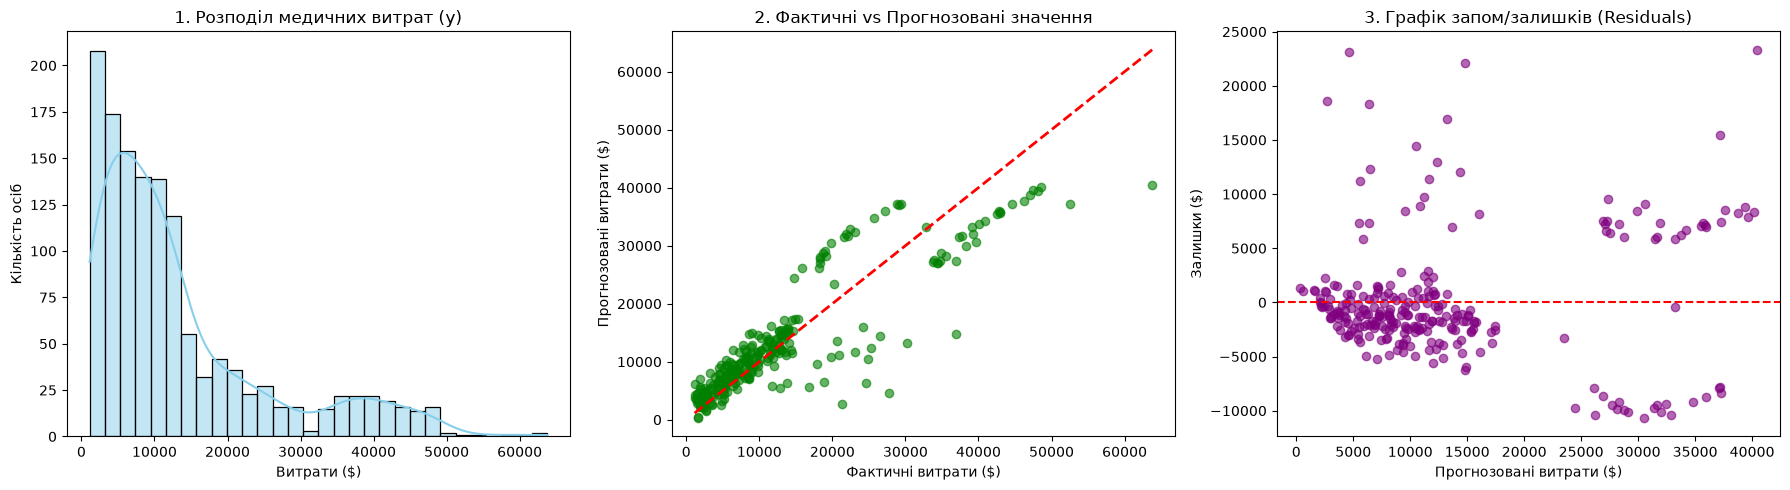

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Розподіл цільової змінної
sns.histplot(y, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('1. Розподіл медичних витрат (y)')
axes[0].set_xlabel('Витрати ($)')
axes[0].set_ylabel('Кількість осіб')

# 2. Фактичні значення проти прогнозованих
axes[1].scatter(y_test, y_pred_lr, alpha=0.6, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_title('2. Фактичні vs Прогнозовані значення')
axes[1].set_xlabel('Фактичні витрати ($)')
axes[1].set_ylabel('Прогнозовані витрати ($)')

# 3. Залишки відносно прогнозу
residuals = y_test - y_pred_lr
axes[2].scatter(y_pred_lr, residuals, alpha=0.6, color='purple')
axes[2].axhline(y=0, color='r', linestyle='--')
axes[2].set_title('3. Графік запом/залишків (Residuals)')
axes[2].set_xlabel('Прогнозовані витрати ($)')
axes[2].set_ylabel('Залишки ($)')

plt.tight_layout()
plt.savefig("visualizations.png", dpi=300)
plt.show()

Збереження результатів у CSV

In [9]:
test_results = X_test.copy()
test_results['y_true'] = y_test
test_results['y_pred'] = y_pred_lr
test_results['residual'] = residuals

test_results.to_csv("test_predictions.csv", index=False)
print("Файл test_predictions.csv успішно збережено!")

Файл test_predictions.csv успішно збережено!


## Висновки
1. **Порівняння з базовою моделлю:** Лінійна регресія значно перевершує `DummyRegressor`. Коефіцієнт детермінації $R^2$ підвищився до значення ~0.75-0.78, що свідчить про те, що модель пояснює понад 75% варіативності медичних витрат.
2. **Аналіз помилок:** Помилки MAE та RMSE істотно зменшилися у порівнянні з базовим прогнозом[cite: 1].
3. **Графік залишків:** На графіку залишків помітна певна структура (групування залишків), що обумовлено нелінійним впливом фактора куріння та BMI на вартість страховки[cite: 1]. Для подальшого покращення моделі доцільно випробувати поліноміальні ознаки або деревні моделі[cite: 1].